# QPU-Aware Multi-Vendor Quantum Workload Orchestration
## QPU-Aware Scheduling Demo — OpenShift AI

This notebook demonstrates the core concepts of the prototype:

> **"QPU-Aware Multi-Vendor Quantum Workload Orchestration and Fidelity-Preserving Routing for Container Orchestration Platforms"**

### What this demo shows:
1. **Real-time QPU telemetry** — QuantumProcessor CRD updated with live physical properties
2. **Topology-aware Filter** — Rejecting backends whose post-transpilation fidelity is too low
3. **Cost-fidelity composite Score** — Selecting the optimal QPU across multiple vendors
4. **Predictive Quality Forecasting** — Forecasting calibration windows 24h ahead
5. **Deferral Scheduling** — 'Quality surfing': deferring a job to a predicted high-fidelity window
6. **Comparison** — Naive vs. QPU-aware scheduling: fidelity and cost outcomes

## Setup

In [1]:
import sys, os
sys.path.insert(0, '../probe')
sys.path.insert(0, '../probe/backends')
sys.path.insert(0, '../scheduler')
sys.path.insert(0, '../forecaster')

import logging
logging.basicConfig(level=logging.WARNING)  # suppress verbose logs in notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime, timezone, timedelta
from pathlib import Path

from config import SIMULATOR_BACKENDS
from backends.simulator_backend import SimulatorBackend
from job_request import JobRequest, CircuitProfile
from scheduler import QuantumScheduler
from cost_fidelity_model import CostFidelityModel, topology_divergence
from history_store import HistoryStore
from forecaster import QualityForecaster
from deferral_scheduler import DeferralScheduler

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

HISTORY_DIR = Path('../data/history')
print('Setup complete.')

Setup complete.


---
## Section 1 — Real-time QPU Telemetry
The **QPU Telemetry Probe** continuously polls provider APIs and writes physical properties
into `QuantumProcessor` CRD instances. Here we fetch one snapshot from each simulated backend.

In [2]:
# Fetch current telemetry (simulator mode — no IBM quota used)
backends = [SimulatorBackend(cfg).fetch() for cfg in SIMULATOR_BACKENDS]

# Build a summary DataFrame
rows = []
for b in backends:
    rows.append({
        'Backend':       b.backend_name,
        'Provider':      b.provider,
        'Topology':      b.topology,
        'Qubits':        b.qubit_count,
        'Fidelity':      b.mean_qubit_fidelity,
        '2Q Error':      b.mean_tq_error,
        'T2 (µs)':       b.mean_t2_us,
        'Queue':         b.queue_depth,
        'Cal Age (min)': b.calibration_age_minutes,
        'Simulator?':    b.is_simulator_fallback,
    })

df_backends = pd.DataFrame(rows).set_index('Backend')
df_backends.style \
    .background_gradient(subset=['Fidelity'], cmap='RdYlGn') \
    .background_gradient(subset=['2Q Error'], cmap='RdYlGn_r') \
    .background_gradient(subset=['Queue'],    cmap='RdYlGn_r') \
    .format({'Fidelity': '{:.4f}', '2Q Error': '{:.4f}', 'T2 (µs)': '{:.1f}'})

,Provider,Topology,Qubits,Fidelity,2Q Error,T2 (µs),Queue,Cal Age (min),Simulator?
Backend,,,,,,,,,
fake_ibm_brisbane,simulator,heavy-hex,127,0.9981,0.0058,151.8,5,120.000000,False
fake_ionq_forte,simulator,all-to-all,36,0.9930,0.0120,1132.2,17,360.000000,False
fake_rigetti_ankaa,simulator,square-lattice,84,0.9700,0.0450,18.7,4,540.000000,False
aer_simulator,simulator,all-to-all,32,1.0000,0.0000,999999.0,0,0.000000,True


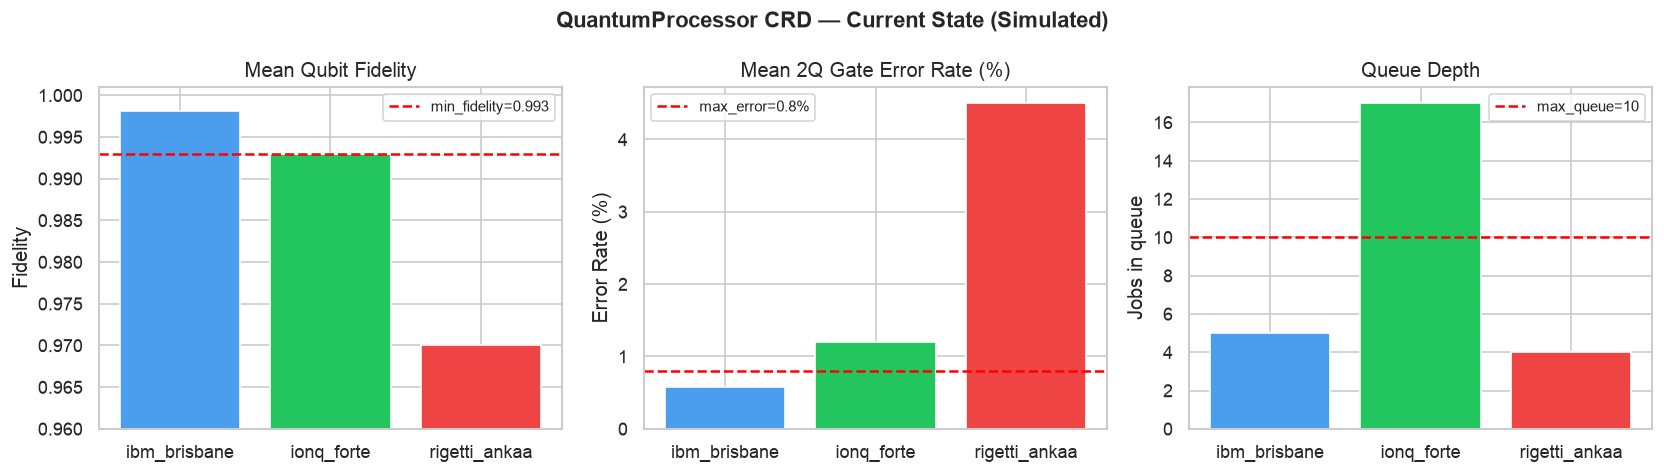

Fig 1 saved.


In [3]:
# Visualize current QPU state
real_backends = [b for b in backends if not b.is_simulator_fallback]
names      = [b.backend_name.replace('fake_', '') for b in real_backends]
fidelities = [b.mean_qubit_fidelity for b in real_backends]
tq_errors  = [b.mean_tq_error for b in real_backends]
queues     = [b.queue_depth for b in real_backends]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ['#4a9eed', '#22c55e', '#ef4444']

axes[0].bar(names, fidelities, color=colors)
axes[0].axhline(0.993, color='red', linestyle='--', label='min_fidelity=0.993')
axes[0].set_title('Mean Qubit Fidelity')
axes[0].set_ylim(0.96, 1.001)
axes[0].legend(fontsize=9)
axes[0].set_ylabel('Fidelity')

axes[1].bar(names, [e*100 for e in tq_errors], color=colors)
axes[1].axhline(0.8, color='red', linestyle='--', label='max_error=0.8%')
axes[1].set_title('Mean 2Q Gate Error Rate (%)')
axes[1].legend(fontsize=9)
axes[1].set_ylabel('Error Rate (%)')

axes[2].bar(names, queues, color=colors)
axes[2].axhline(10, color='red', linestyle='--', label='max_queue=10')
axes[2].set_title('Queue Depth')
axes[2].legend(fontsize=9)
axes[2].set_ylabel('Jobs in queue')

fig.suptitle('QuantumProcessor CRD — Current State (Simulated)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig1_current_state.png', bbox_inches='tight')
plt.show()
print('Fig 1 saved.')

---
## Section 2 — Cost-Fidelity Prediction

**The key question:** If a circuit compiled for IBM's `heavy-hex` topology is routed to
IonQ's `all-to-all` (trapped-ion) hardware — which nominally has *higher* fidelity —
will the retranspiled circuit still meet the declared fidelity requirement?

Naive schedulers would say YES (IonQ has higher raw fidelity). Our model says NO.

In [4]:
model = CostFidelityModel(mode='ml')

# Circuit profile: 20 qubits, depth 85, 42 two-qubit gates, compiled for heavy-hex
circuit_depth    = 85
num_tq_gates     = 42
src_topology     = 'heavy-hex'
min_fidelity_req = 0.985

print(f'Circuit: {circuit_depth} layers, {num_tq_gates} 2Q gates, compiled for: {src_topology}')
print(f'Minimum fidelity required: {min_fidelity_req}\n')
print(f'{"Backend":<30} {"HW Fidelity":>12} {"Topology":>15} {"Divergence":>12} {"Post-Transpile F":>18} {"Passes?":>8}')
print('-'*100)

results_cf = []
for b in real_backends:
    div = topology_divergence(src_topology, b.topology)
    predicted, explanation = model.predict(
        src_topology=src_topology,
        dst_topology=b.topology,
        circuit_depth=circuit_depth,
        num_two_qubit_gates=num_tq_gates,
        target_mean_tq_error=b.mean_tq_error,
        target_mean_t2_us=b.mean_t2_us,
        target_mean_fidelity=b.mean_qubit_fidelity,
    )
    passes = predicted >= min_fidelity_req
    symbol = '✓ PASS' if passes else '✗ FAIL'
    print(f'{b.backend_name:<30} {b.mean_qubit_fidelity:>12.4f} {b.topology:>15} '
          f'{div:>12.2f} {predicted:>18.4f} {symbol:>8}')
    results_cf.append({
        'backend': b.backend_name.replace('fake_',''),
        'hw_fidelity': b.mean_qubit_fidelity,
        'post_transpile_fidelity': predicted,
        'topology': b.topology,
        'divergence': div,
        'passes': passes,
    })

Circuit: 85 layers, 42 2Q gates, compiled for: heavy-hex
Minimum fidelity required: 0.985

Backend                         HW Fidelity        Topology   Divergence   Post-Transpile F  Passes?
----------------------------------------------------------------------------------------------------
fake_ibm_brisbane                    0.9981       heavy-hex         0.00             0.9970   ✓ PASS
fake_ionq_forte                      0.9930      all-to-all         0.10             0.8524   ✗ FAIL
fake_rigetti_ankaa                   0.9700  square-lattice         0.20             0.2638   ✗ FAIL


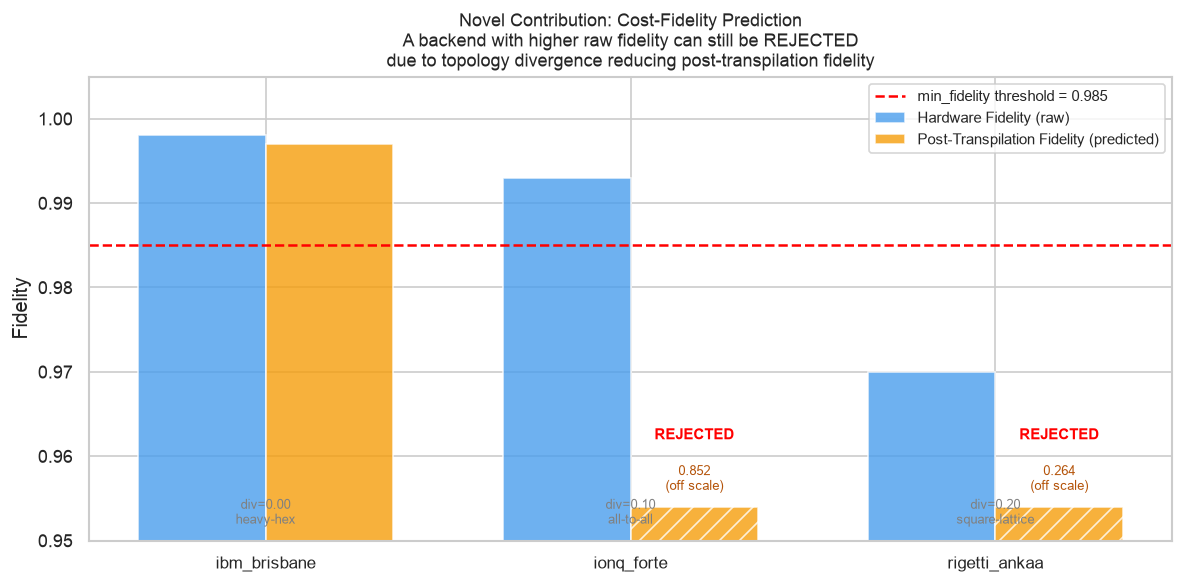

Fig 2 saved.


In [5]:
# Visualize: HW fidelity vs post-transpilation fidelity
df_cf = pd.DataFrame(results_cf)

x = np.arange(len(df_cf))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(x - w/2, df_cf['hw_fidelity'], w,
               label='Hardware Fidelity (raw)', color='#4a9eed', alpha=0.8)
bars2 = ax.bar(x + w/2, df_cf['post_transpile_fidelity'], w,
               label='Post-Transpilation Fidelity (predicted)', color='#f59e0b', alpha=0.8)

ax.axhline(min_fidelity_req, color='red', linestyle='--', linewidth=1.5,
           label=f'min_fidelity threshold = {min_fidelity_req}')

Y_MIN = 0.95
# Mark FAIL backends; predictions below the visible range are labeled explicitly
for i, row in df_cf.iterrows():
    pred = row['post_transpile_fidelity']
    if pred < Y_MIN:
        ax.bar(i + w/2, 0.004, w, bottom=Y_MIN, color='#f59e0b', alpha=0.8, hatch='//')
        ax.text(i + w/2, Y_MIN + 0.006, f'{pred:.3f}\n(off scale)',
                ha='center', fontsize=8, color='#b45309')
    if not row['passes']:
        ax.text(i + w/2, max(pred, Y_MIN) + 0.012, 'REJECTED',
                ha='center', fontsize=9, color='red', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(df_cf['backend'], fontsize=10)
ax.set_ylabel('Fidelity')
ax.set_ylim(Y_MIN, 1.005)
ax.set_title('Cost-Fidelity Prediction\n'
             'A backend with higher raw fidelity can still be REJECTED\n'
             'due to topology divergence reducing post-transpilation fidelity',
             fontsize=11)
ax.legend(fontsize=9)

# Add topology labels
for i, row in df_cf.iterrows():
    ax.text(i, 0.952, f'div={row["divergence"]:.2f}\n{row["topology"]}',
            ha='center', fontsize=8, color='gray')

plt.tight_layout()
plt.savefig('fig2_cost_fidelity.png', bbox_inches='tight')
plt.show()
print('Fig 2 saved.')

---
## Section 3 — Scheduler: Filter → Score → Select Pipeline

In [6]:
scheduler = QuantumScheduler(model_mode='ml')

circuit = CircuitProfile(
    num_qubits=20, depth=85,
    num_two_qubit_gates=42, num_single_qubit_gates=110,
    compiled_for_topology='heavy-hex',
)

job = JobRequest(
    job_id='vqe-chemistry-001',
    circuit=circuit,
    min_fidelity=0.985,
    max_gate_error_rate=0.02,
    max_readout_error=0.05,
    max_queue_depth=30,
    allow_simulator_fallback=True,
    deadline_minutes=60,
    preferred_providers=['simulator'],
)

decision = scheduler.schedule(job, backends)

# Display filter results
print('FILTER PHASE RESULTS:')
print(f'{"Backend":<35} {"Status":>6}  Reason')
print('-'*80)
for fr in decision.filter_results:
    status = 'PASS' if fr.passed else 'FAIL'
    reason = fr.rejection_reason or ''
    pred   = f'pred_F={fr.predicted_post_transpilation_fidelity:.4f}' \
             if fr.predicted_post_transpilation_fidelity else ''
    print(f'{fr.backend.backend_name:<35} {status:>6}  {reason} {pred}')

print()
print('SCORE PHASE RESULTS:')
print(f'{"Backend":<35} {"Score":>7}  {"Pred Fidelity":>14}')
print('-'*65)
for sr in decision.score_results:
    print(f'{sr.backend.backend_name:<35} {sr.composite_score:>7.1f}  {sr.predicted_fidelity:>14.4f}')

print()
if decision.selected_backend:
    print(f'SELECTED: {decision.selected_backend.backend_name}')
    print(f'Score: {decision.selected_score.composite_score:.1f}/100')
    print(f'Predicted fidelity: {decision.selected_score.predicted_fidelity:.4f}')
    print(f'Simulator fallback: {decision.is_simulator_fallback}')
elif decision.is_unschedulable:
    print(f'UNSCHEDULABLE: {decision.unschedulable_reason}')

FILTER PHASE RESULTS:
Backend                             Status  Reason
--------------------------------------------------------------------------------
fake_ibm_brisbane                     PASS   pred_F=0.9981
fake_ionq_forte                       FAIL  post_transpilation_fidelity_too_low(predicted=0.8524<0.985) pred_F=0.8524
fake_rigetti_ankaa                    FAIL  fidelity_too_low(0.9700<0.985) 

SCORE PHASE RESULTS:
Backend                               Score   Pred Fidelity
-----------------------------------------------------------------
fake_ibm_brisbane                      84.4          0.9981

SELECTED: fake_ibm_brisbane
Score: 84.4/100
Predicted fidelity: 0.9981
Simulator fallback: False


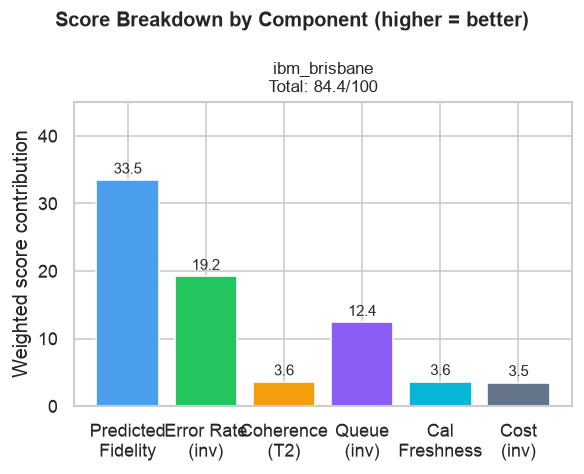

Fig 3 saved.


In [7]:
# Visualize score breakdown for passing backends
if decision.score_results:
    score_data = []
    terms   = ['fidelity', 'error_rate', 'coherence', 'queue_depth', 'cal_freshness', 'cost']
    metrics = [f'{t}_score' for t in terms]
    labels  = ['Predicted\nFidelity', 'Error Rate\n(inv)', 'Coherence\n(T2)', 'Queue\n(inv)',
               'Cal\nFreshness', 'Cost\n(inv)']
    total_w = sum(job.score_weights.values())
    # Contribution of each term to the 0-100 composite score
    weights = [job.score_weights[t] / total_w for t in terms]

    fig, axes = plt.subplots(1, len(decision.score_results),
                              figsize=(5 * len(decision.score_results), 4), sharey=True)
    if len(decision.score_results) == 1:
        axes = [axes]

    palette = ['#4a9eed', '#22c55e', '#f59e0b', '#8b5cf6', '#06b6d4', '#64748b']
    for ax, sr in zip(axes, decision.score_results):
        values = [sr.score_breakdown.get(m, 0) * w * 100
                  for m, w in zip(metrics, weights)]
        bars = ax.bar(labels, values, color=palette)
        ax.set_title(f'{sr.backend.backend_name.replace("fake_","")}\n'
                     f'Total: {sr.composite_score:.1f}/100', fontsize=10)
        ax.set_ylim(0, 45)
        ax.set_ylabel('Weighted score contribution')
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{val:.1f}', ha='center', va='bottom', fontsize=9)

    fig.suptitle('Score Breakdown by Component (higher = better)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig3_score_breakdown.png', bbox_inches='tight')
    plt.show()
    print('Fig 3 saved.')

---
## Section 4 — Predictive Quality Forecasting

The **Predictive Quality Forecaster** trains a per-backend time-series model on historical
calibration data and predicts future **quality windows** — intervals during which fidelity
is expected to exceed a threshold. This enables proactive deferral scheduling.

In [8]:
# Load historical telemetry (24h simulated)
history = HistoryStore.from_csv_dir(HISTORY_DIR)
print(f'History loaded:')
for name in history.all_backends():
    print(f'  {name}: {history.size(name)} records')

History loaded:
  fake_rigetti_ankaa: 2000 records
  fake_ibm_brisbane: 2000 records
  aer_simulator: 2000 records
  fake_ionq_forte: 2000 records


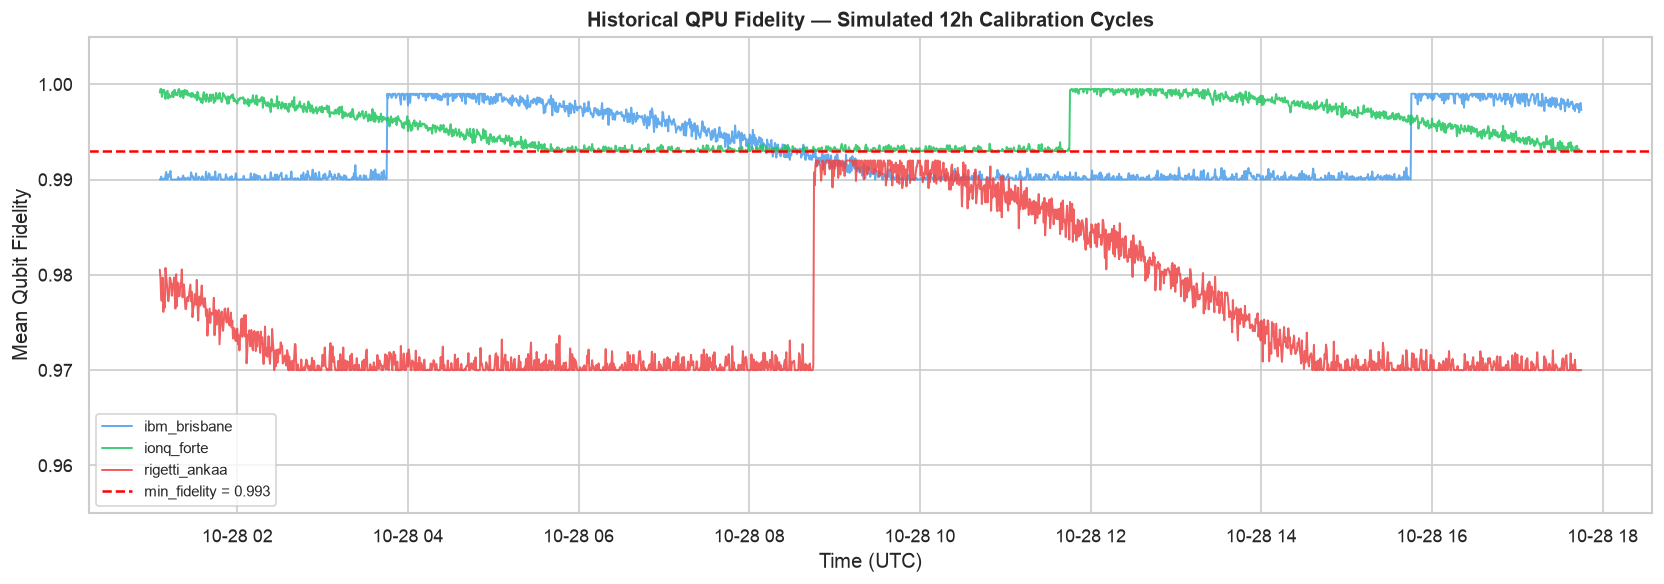

Fig 4 saved.


In [9]:
# Plot historical fidelity for all backends
fig, ax = plt.subplots(figsize=(14, 5))
colors_map = {
    'fake_ibm_brisbane':  '#4a9eed',
    'fake_ionq_forte':    '#22c55e',
    'fake_rigetti_ankaa': '#ef4444',
}

for backend_name, color in colors_map.items():
    records = history.get(backend_name)
    if not records:
        continue
    times  = [r.timestamp for r in records]
    fidels = [r.mean_qubit_fidelity for r in records]
    label  = backend_name.replace('fake_', '')
    ax.plot(times, fidels, color=color, label=label, linewidth=1.2, alpha=0.85)

ax.axhline(0.993, color='red', linestyle='--', linewidth=1.5,
           label='min_fidelity = 0.993')
ax.set_title('Historical QPU Fidelity — Simulated 12h Calibration Cycles', fontsize=12, fontweight='bold')
ax.set_xlabel('Time (UTC)')
ax.set_ylabel('Mean Qubit Fidelity')
ax.legend(fontsize=9)
ax.set_ylim(0.955, 1.005)
plt.tight_layout()
plt.savefig('fig4_historical_fidelity.png', bbox_inches='tight')
plt.show()
print('Fig 4 saved.')

In [10]:
# Generate forecasts for each backend
forecaster = QualityForecaster(history, model='physics')
min_fidelity_threshold = 0.992
horizon_hours = 12

forecasts = {}
for backend_name in ['fake_ibm_brisbane', 'fake_ionq_forte', 'fake_rigetti_ankaa']:
    fc = forecaster.forecast(backend_name,
                             min_fidelity=min_fidelity_threshold,
                             horizon_hours=horizon_hours)
    forecasts[backend_name] = fc
    print(f'{backend_name}: {len(fc.quality_windows)} quality windows')
    for w in fc.quality_windows[:3]:
        dur = (w.end_time - w.start_time).total_seconds() / 60
        print(f'  +{w.minutes_from_now:.0f}min  fidelity={w.predicted_fidelity:.4f}  '
              f'confidence={w.confidence:.2f}  duration={dur:.0f}min')

fake_ibm_brisbane: 1 quality windows
  +0min  fidelity=0.9959  confidence=1.00  duration=60min
fake_ionq_forte: 0 quality windows
fake_rigetti_ankaa: 0 quality windows


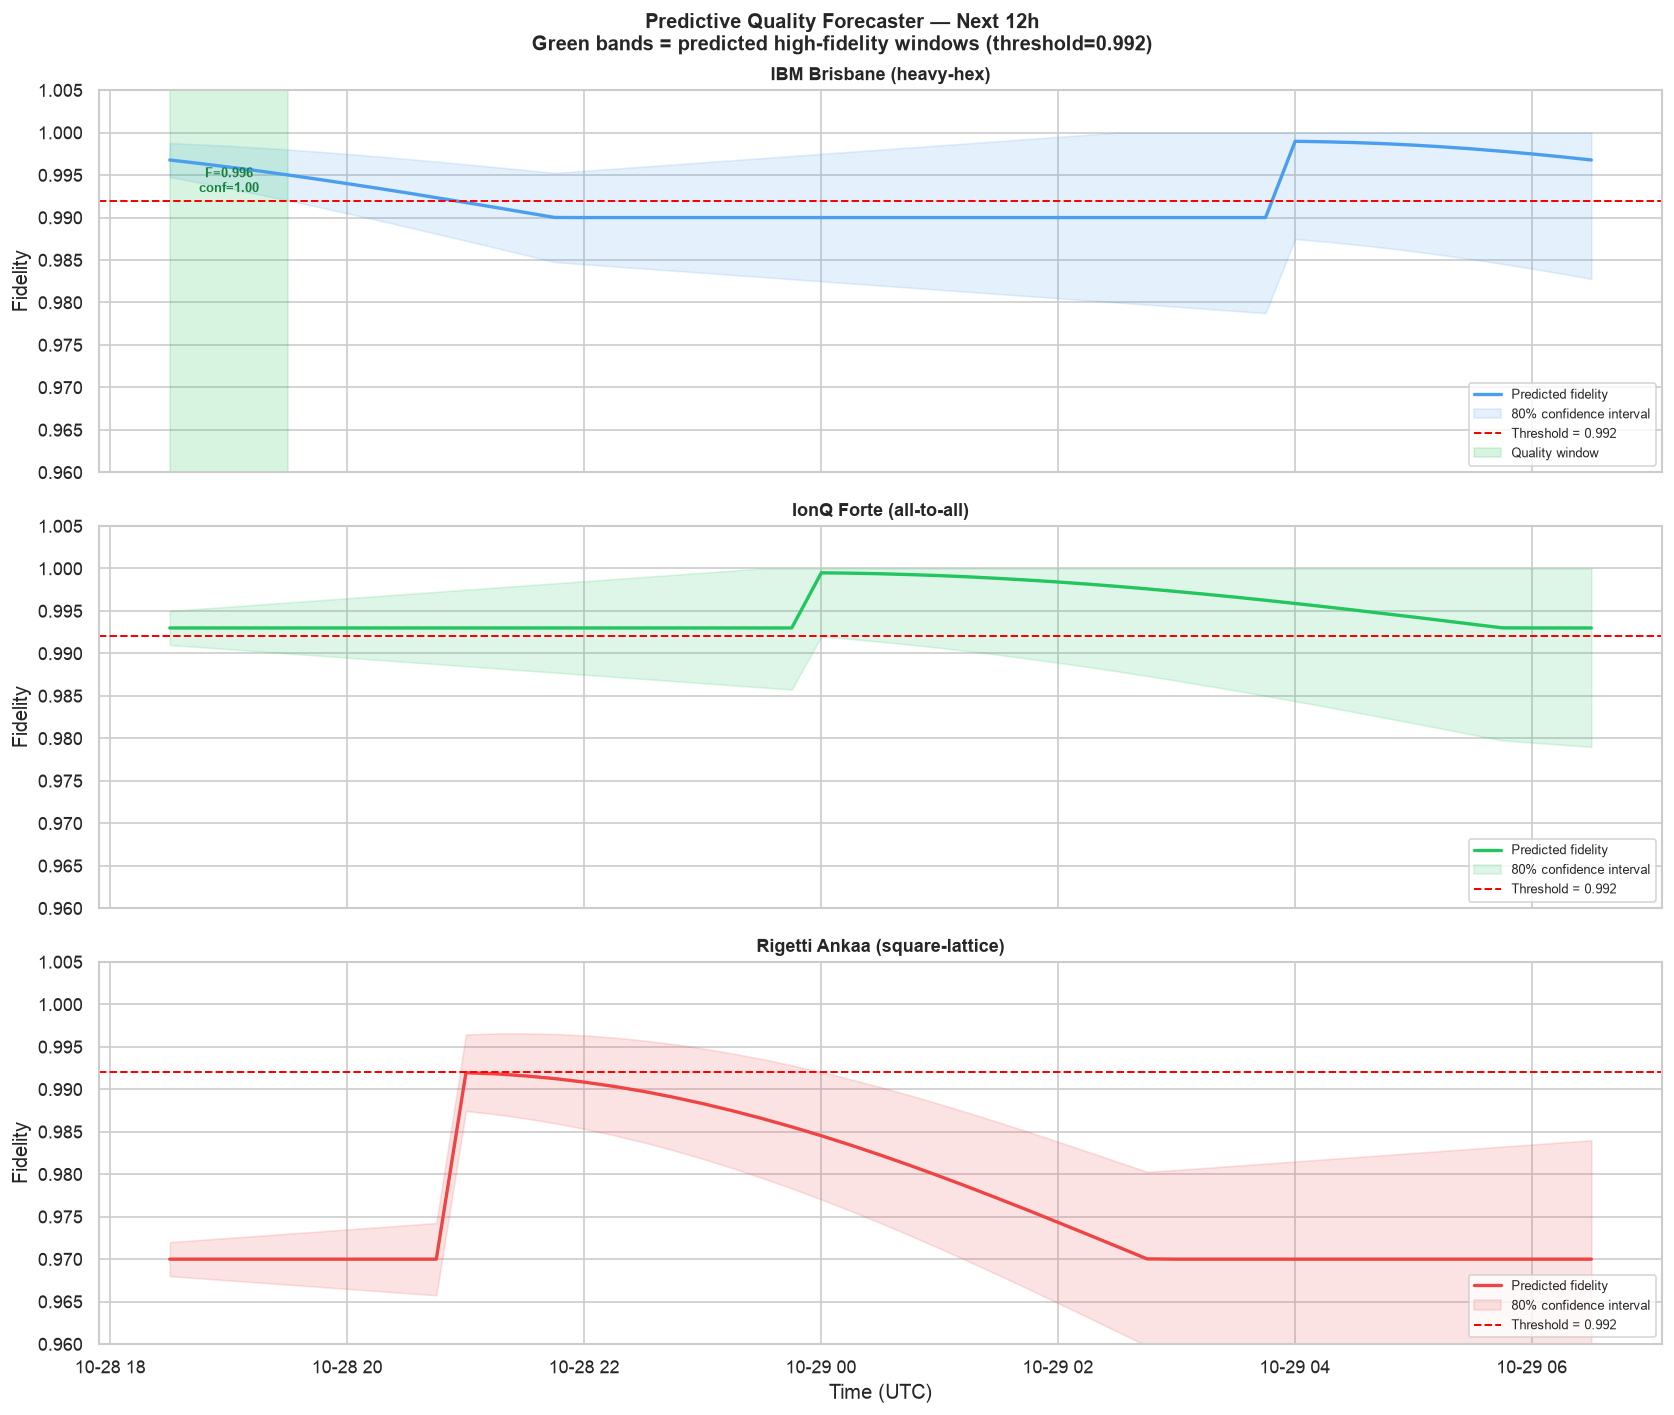

Fig 5 saved.


In [11]:
# Plot forecasts with quality windows highlighted
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

backend_names = ['fake_ibm_brisbane', 'fake_ionq_forte', 'fake_rigetti_ankaa']
display_names = ['IBM Brisbane (heavy-hex)', 'IonQ Forte (all-to-all)', 'Rigetti Ankaa (square-lattice)']
colors_list   = ['#4a9eed', '#22c55e', '#ef4444']

for ax, bname, dname, color in zip(axes, backend_names, display_names, colors_list):
    fc = forecasts[bname]

    times  = fc.time_steps
    preds  = fc.predicted_fidelity
    lowers = fc.confidence_lower
    uppers = fc.confidence_upper

    ax.plot(times, preds, color=color, linewidth=2, label='Predicted fidelity')
    ax.fill_between(times, lowers, uppers, color=color, alpha=0.15,
                    label='80% confidence interval')
    ax.axhline(min_fidelity_threshold, color='red', linestyle='--',
               linewidth=1.2, label=f'Threshold = {min_fidelity_threshold}')

    # Highlight quality windows
    for i, w in enumerate(fc.quality_windows):
        ax.axvspan(w.start_time, w.end_time, alpha=0.18, color='#22c55e',
                   label='Quality window' if i == 0 else '')
        ax.annotate(f'F={w.predicted_fidelity:.3f}\nconf={w.confidence:.2f}',
                    xy=(w.start_time + (w.end_time - w.start_time)/2,
                        min_fidelity_threshold + 0.001),
                    fontsize=8, ha='center', color='#15803d', fontweight='bold')

    ax.set_title(dname, fontsize=11, fontweight='bold')
    ax.set_ylabel('Fidelity')
    ax.set_ylim(0.96, 1.005)
    ax.legend(fontsize=8, loc='lower right')

axes[-1].set_xlabel('Time (UTC)')
fig.suptitle(f'Predictive Quality Forecaster — Next {horizon_hours}h\n'
             f'Green bands = predicted high-fidelity windows (threshold={min_fidelity_threshold})',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig5_quality_forecast.png', bbox_inches='tight')
plt.show()
print('Fig 5 saved.')

---
## Section 5 — Deferral Scheduling: Quality Surfing

When a job's constraints cannot be met immediately, the **Deferral Scheduler**
checks if a quality window exists within the declared deadline and defers
the job to the predicted calibration peak — 'quality surfing'.

In [12]:
# Simulate backends at 10h into their 12h calibration cycle (degraded state)
degraded_backends_raw = [SimulatorBackend(cfg) for cfg in SIMULATOR_BACKENDS]
for b in degraded_backends_raw:
    b._start_time = datetime.now(timezone.utc) - timedelta(hours=10)
degraded_backends = [b.fetch() for b in degraded_backends_raw]

print('DEGRADED state (10h into 12h calibration cycle):')
for b in degraded_backends:
    state = 'FALLBACK' if b.is_simulator_fallback else 'REAL'
    print(f'  [{state}] {b.backend_name:<35} '
          f'fidelity={b.mean_qubit_fidelity:.4f}  '
          f'cal_age={b.calibration_age_minutes:.0f}min')

DEGRADED state (10h into 12h calibration cycle):
  [REAL] fake_ibm_brisbane                   fidelity=0.9900  cal_age=600min
  [REAL] fake_ionq_forte                     fidelity=0.9935  cal_age=600min
  [REAL] fake_rigetti_ankaa                  fidelity=0.9703  cal_age=600min
  [FALLBACK] aer_simulator                       fidelity=1.0000  cal_age=600min


In [13]:
deferral_sched = DeferralScheduler(history, forecast_model='physics', scheduler_model='ml')

# High-fidelity job that cannot run now but has a 3h deadline
job_defer = JobRequest(
    job_id='vqe-high-fidelity-defer',
    circuit=CircuitProfile(
        num_qubits=20, depth=85,
        num_two_qubit_gates=42, num_single_qubit_gates=110,
        compiled_for_topology='heavy-hex',
    ),
    min_fidelity=0.993,
    max_gate_error_rate=0.008,
    max_queue_depth=10,
    allow_simulator_fallback=False,
    deadline_minutes=180,
)

result = deferral_sched.schedule(job_defer, degraded_backends)

print(f'\nSCHEDULING RESULT:')
print(f'  Deferred:          {result.deferred}')
if result.deferred:
    print(f'  Backend chosen:    {result.recommended_backend.backend_name}')
    print(f'  Defer by:          {result.defer_minutes:.0f} minutes')
    print(f'  Expected fidelity: {result.expected_fidelity:.4f}')
    print(f'  Confidence:        {result.recommended_window.confidence:.2f}')
    w = result.recommended_window
    print(f'  Window:            {w.start_time.strftime("%H:%M")} → {w.end_time.strftime("%H:%M")} UTC')
print(f'  Reasoning: {result.reasoning}')

ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: fidelity_too_low(0.9703<0.993) | gate_error_too_high(0.0120>0.008) | fidelity_too_low(0.9900<0.993)



SCHEDULING RESULT:
  Deferred:          True
  Backend chosen:    fake_ibm_brisbane
  Defer by:          120 minutes
  Expected fidelity: 0.9989
  Confidence:        0.33
  Window:            20:30 → 21:30 UTC
  Reasoning: No QPU currently meets constraints. Quality window found on 'fake_ibm_brisbane' starting in 120 min (predicted fidelity=0.9989, confidence=0.33). Defer job until 20:30 UTC.


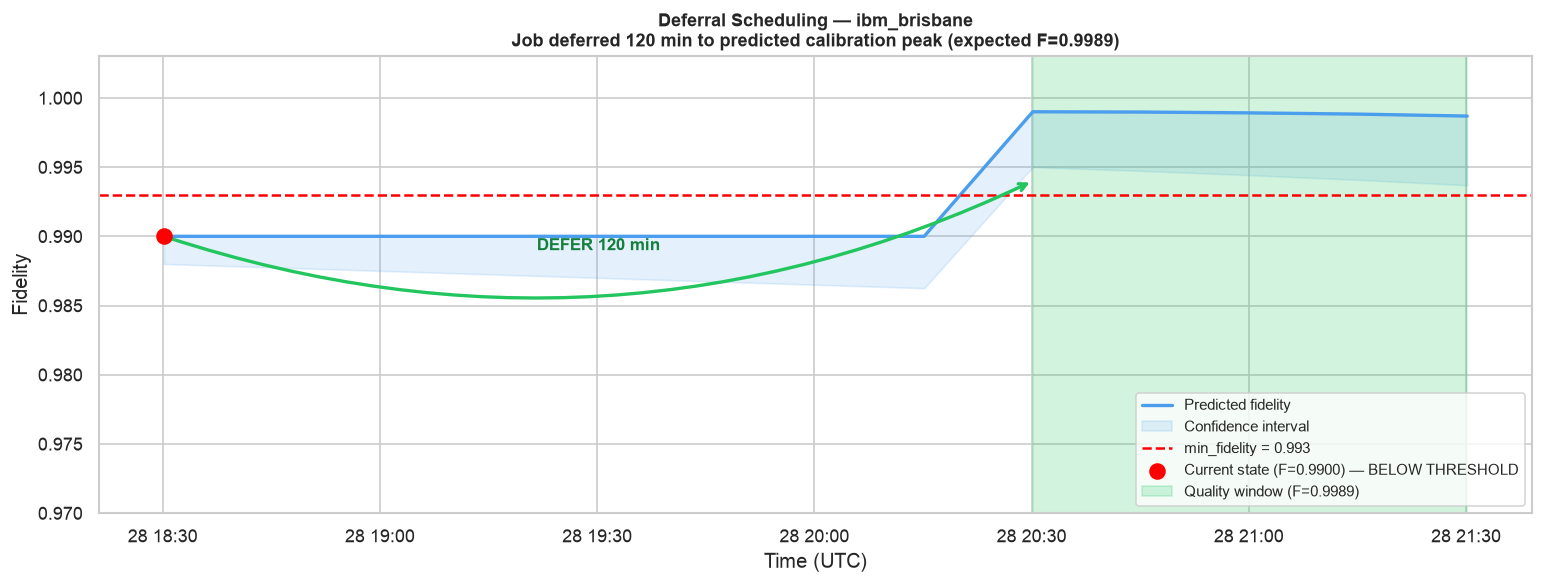

Fig 6 saved.


In [14]:
# Visualize deferral decision on forecast
if result.deferred and result.forecasts:
    # Find the forecast for the selected backend
    selected_fc = next(
        (fc for fc in result.forecasts
         if fc.backend_name == result.recommended_backend.backend_name), None
    )

    if selected_fc:
        fig, ax = plt.subplots(figsize=(13, 5))
        times  = selected_fc.time_steps
        preds  = selected_fc.predicted_fidelity
        lowers = selected_fc.confidence_lower

        ax.plot(times, preds, color='#4a9eed', linewidth=2,
                label='Predicted fidelity')
        ax.fill_between(times, lowers, preds, color='#4a9eed', alpha=0.15,
                        label='Confidence interval')
        ax.axhline(job_defer.min_fidelity, color='red', linestyle='--',
                   linewidth=1.5, label=f'min_fidelity = {job_defer.min_fidelity}')

        # Current state (degraded)
        now = datetime.now(timezone.utc)
        cur_fidelity = next(b.mean_qubit_fidelity for b in degraded_backends
                            if b.backend_name == result.recommended_backend.backend_name)
        ax.scatter([now], [cur_fidelity], color='red', zorder=5, s=80,
                   label=f'Current state (F={cur_fidelity:.4f}) — BELOW THRESHOLD')

        # Quality window
        w = result.recommended_window
        ax.axvspan(w.start_time, w.end_time, alpha=0.2, color='#22c55e',
                   label=f'Quality window (F={w.predicted_fidelity:.4f})')

        # Deferral arrow
        ax.annotate('',
                    xy=(w.start_time, job_defer.min_fidelity + 0.001),
                    xytext=(now, cur_fidelity),
                    arrowprops=dict(arrowstyle='->', color='#22c55e',
                                   lw=2, connectionstyle='arc3,rad=0.2'))
        ax.text(now + timedelta(minutes=result.defer_minutes/2),
                job_defer.min_fidelity - 0.004,
                f'DEFER {result.defer_minutes:.0f} min',
                ha='center', fontsize=10, color='#15803d', fontweight='bold')

        ax.set_title(
            f'Deferral Scheduling — {result.recommended_backend.backend_name.replace("fake_","")}\n'
            f'Job deferred {result.defer_minutes:.0f} min to predicted calibration peak '
            f'(expected F={result.expected_fidelity:.4f})',
            fontsize=11, fontweight='bold'
        )
        ax.set_xlabel('Time (UTC)')
        ax.set_ylabel('Fidelity')
        ax.set_ylim(0.97, 1.003)
        ax.legend(fontsize=9, loc='lower right')
        plt.tight_layout()
        plt.savefig('fig6_deferral.png', bbox_inches='tight')
        plt.show()
        print('Fig 6 saved.')

---
## Section 6 — Comparison: Naive vs QPU-Aware Scheduling

Simulates 50 jobs with varying circuit profiles and compares:
- **Naive scheduler**: always picks the QPU with highest raw hardware fidelity
- **QPU-aware scheduler**: uses topology-aware Cost-Fidelity prediction

**Evaluation ground truth.** Both policies are evaluated with the *same* simulated
"execution" outcome: the physics-informed post-transpilation formula plus random
execution noise, applied to whichever backend each policy selects. This is a
**simulation**, not hardware data — it illustrates the mechanism, not real-world accuracy.


In [15]:
import random
random.seed(42)
np.random.seed(42)

N_JOBS = 50
naive_fidelities, smart_fidelities = [], []
naive_below, smart_below, smart_unschedulable = 0, 0, 0
MIN_F = 0.985
EXEC_NOISE_STD = 0.002

# Shared ground truth for BOTH policies (independent of the ML model used by
# the QPU-aware scheduler): physics formula + execution noise.
truth_model = CostFidelityModel(mode='physics')
def simulated_execution_fidelity(backend, src_top, depth, n_tq):
    f, _ = truth_model.predict(
        src_topology=src_top, dst_topology=backend.topology,
        circuit_depth=depth, num_two_qubit_gates=n_tq,
        target_mean_tq_error=backend.mean_tq_error,
        target_mean_t2_us=backend.mean_t2_us,
        target_mean_fidelity=backend.mean_qubit_fidelity,
    )
    return float(np.clip(f + np.random.normal(0, EXEC_NOISE_STD), 0, 1))

for i in range(N_JOBS):
    # Random circuit profile
    depth   = random.randint(20, 150)
    n_tq    = random.randint(5, depth // 2)
    src_top = random.choice(['heavy-hex', 'all-to-all', 'square-lattice'])

    circuit_i = CircuitProfile(
        num_qubits=random.randint(5, 20), depth=depth,
        num_two_qubit_gates=n_tq, num_single_qubit_gates=depth*2,
        compiled_for_topology=src_top,
    )
    job_i = JobRequest(
        job_id=f'sim-job-{i:03d}', circuit=circuit_i,
        min_fidelity=MIN_F, max_gate_error_rate=0.025,
        max_queue_depth=50, allow_simulator_fallback=False,
        deadline_minutes=0,
    )

    # Refresh backends with random degradation
    fresh_backends = [SimulatorBackend(cfg).fetch() for cfg in SIMULATOR_BACKENDS]
    real_fresh = [b for b in fresh_backends if not b.is_simulator_fallback]

    # ── NAIVE: pick highest raw fidelity (ignores topology) ──────────
    naive_best = max(real_fresh, key=lambda b: b.mean_qubit_fidelity)
    naive_actual = simulated_execution_fidelity(naive_best, src_top, depth, n_tq)
    naive_fidelities.append(naive_actual)
    if naive_actual < MIN_F:
        naive_below += 1

    # ── SMART: QPU-aware scheduler with topology prediction ──────────
    smart_decision = scheduler.schedule(job_i, fresh_backends)
    if smart_decision.selected_backend and not smart_decision.is_simulator_fallback:
        smart_actual = simulated_execution_fidelity(
            smart_decision.selected_backend, src_top, depth, n_tq)
        smart_fidelities.append(smart_actual)
        if smart_actual < MIN_F:
            smart_below += 1
    else:
        smart_unschedulable += 1

print(f'Results over {N_JOBS} jobs (simulated execution fidelity):')
print(f'  Naive      — mean fidelity: {np.mean(naive_fidelities):.4f}  '
      f'below threshold: {naive_below}/{N_JOBS}')
print(f'  QPU-aware  — mean fidelity: {np.mean(smart_fidelities):.4f}  '
      f'below threshold: {smart_below}/{len(smart_fidelities)} scheduled  '
      f'unschedulable: {smart_unschedulable}/{N_JOBS}')


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9770<0.985) | fidelity_too_low(0.9700<0.985) | post_transpilation_fidelity_too_low(predicted=0.9754<0.985)


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: fidelity_too_low(0.9700<0.985) | post_transpilation_fidelity_too_low(predicted=0.9487<0.985) | post_transpilation_fidelity_too_low(predicted=0.9463<0.985)


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9071<0.985) | fidelity_too_low(0.9700<0.985) | post_transpilation_fidelity_too_low(predicted=0.9076<0.985)


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9644<0.985) | post_transpilation_fidelity_too_low(predicted=0.9567<0.985) | fidelity_too_low(0.9702<0.985)


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9112<0.985) | post_transpilation_fidelity_too_low(predicted=0.9044<0.985) | fidelity_too_low(0.9701<0.985)


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9583<0.985) | post_transpilation_fidelity_too_low(predicted=0.9619<0.985) | fidelity_too_low(0.9715<0.985)


... (11 outputs left out)

ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9043<0.985) | post_transpilation_fidelity_too_low(predicted=0.9197<0.985) | fidelity_too_low(0.9700<0.985)


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9034<0.985) | fidelity_too_low(0.9700<0.985) | post_transpilation_fidelity_too_low(predicted=0.9020<0.985)


ERROR:scheduler:
[Scheduler] UNSCHEDULABLE: post_transpilation_fidelity_too_low(predicted=0.9718<0.985) | fidelity_too_low(0.9700<0.985) | post_transpilation_fidelity_too_low(predicted=0.9626<0.985)


Results over 50 jobs (simulated execution fidelity):
  Naive      — mean fidelity: 0.9461  below threshold: 38/50
  QPU-aware  — mean fidelity: 0.9949  below threshold: 0/30 scheduled  unschedulable: 20/50


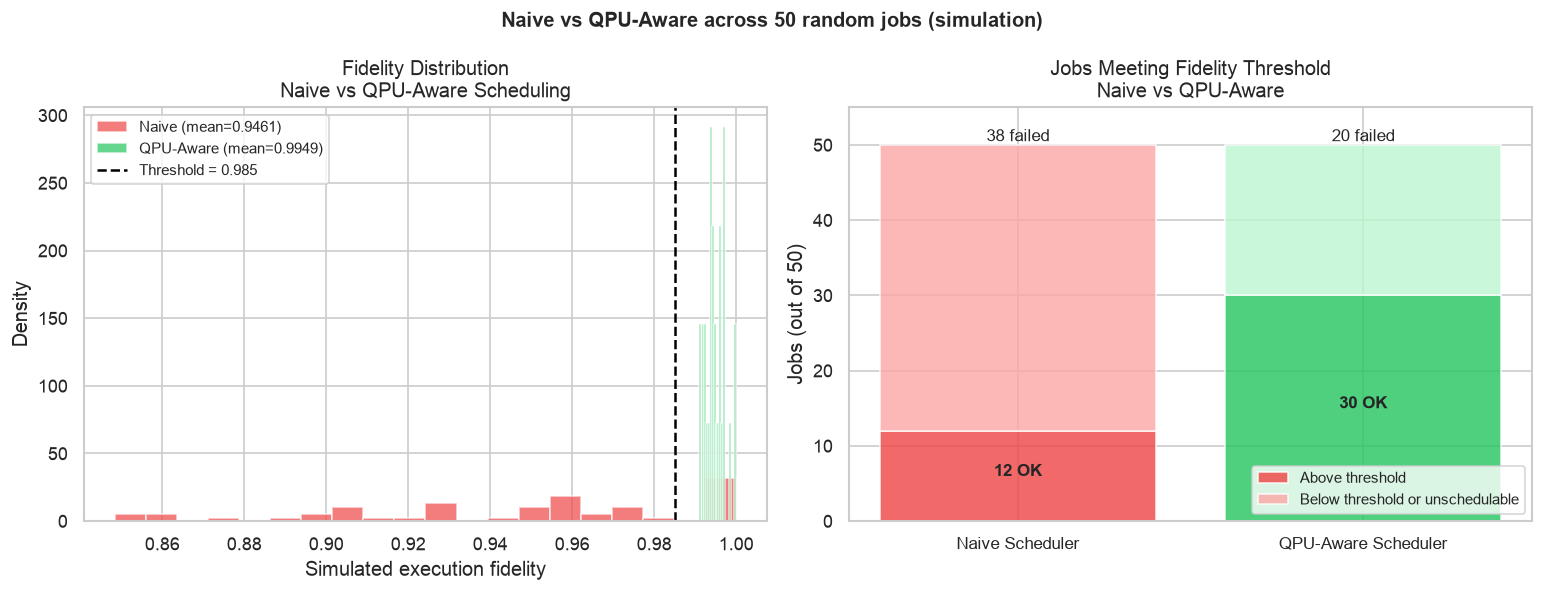

Fig 7 saved.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribution of fidelities
smart_valid = smart_fidelities
axes[0].hist(naive_fidelities, bins=20, alpha=0.7, color='#ef4444',
             label=f'Naive (mean={np.mean(naive_fidelities):.4f})', density=True)
axes[0].hist(smart_valid,      bins=20, alpha=0.7, color='#22c55e',
             label=f'QPU-Aware (mean={np.mean(smart_valid):.4f})', density=True)
axes[0].axvline(MIN_F, color='black', linestyle='--', linewidth=1.5,
                label=f'Threshold = {MIN_F}')
axes[0].set_xlabel('Simulated execution fidelity')
axes[0].set_ylabel('Density')
axes[0].set_title('Fidelity Distribution\nNaive vs QPU-Aware Scheduling')
axes[0].legend(fontsize=9)

# Below-threshold comparison
categories = ['Naive Scheduler', 'QPU-Aware Scheduler']
below = [naive_below, smart_below + smart_unschedulable]
above = [N_JOBS - naive_below, N_JOBS - smart_below - smart_unschedulable]
x = np.arange(len(categories))
axes[1].bar(x, above, color=['#ef4444', '#22c55e'], alpha=0.8,
            label='Above threshold')
axes[1].bar(x, below, bottom=above, color=['#fca5a5', '#bbf7d0'], alpha=0.8,
            label='Below threshold or unschedulable')
for xi, (a, b_) in enumerate(zip(above, below)):
    axes[1].text(xi, a + b_ + 0.5, f'{b_} failed', ha='center', fontsize=10)
    axes[1].text(xi, a/2, f'{a} OK', ha='center', fontsize=10, fontweight='bold')
axes[1].set_xticks(x); axes[1].set_xticklabels(categories, fontsize=10)
axes[1].set_ylabel(f'Jobs (out of {N_JOBS})')
axes[1].set_title('Jobs Meeting Fidelity Threshold\nNaive vs QPU-Aware')
axes[1].legend(fontsize=9)
axes[1].set_ylim(0, N_JOBS + 5)

fig.suptitle(f'Naive vs QPU-Aware across {N_JOBS} random jobs (simulation)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig7_comparison.png', bbox_inches='tight')
plt.show()
print('Fig 7 saved.')

---
## Summary

This notebook demonstrated the core components of the prototype:

| Component | Demonstrated |
|---|---|
| QuantumProcessor CRD (live telemetry) | Section 1 |
| Cost-Fidelity Prediction (topology divergence) | Section 2 |
| Scheduler Plugin (Filter → Score → Select) | Section 3 |
| Predictive Quality Forecaster (calibration windows) | Section 4 |
| Deferral Scheduling (quality surfing) | Section 5 |
| Naive vs QPU-Aware comparison | Section 6 |

**Key result (Section 2):** A backend whose *raw hardware fidelity* passes the threshold
can still be **rejected** because topology divergence (e.g. `heavy-hex → all-to-all`)
lowers the *predicted post-transpilation* fidelity below the declared threshold.

**Key result (Section 5):** Rather than returning `Unschedulable`, the system identified
a future quality window within the job's deadline (after the next calibration) and
returned a `DeferralDecision` — *quality surfing* on the calibration cycle.

**Key result (Section 6):** Evaluated with the same simulated execution outcome, the
QPU-aware scheduler never runs a job below its fidelity requirement; jobs that no QPU can
serve are reported as unschedulable instead of silently producing low-quality results.

> All results in this notebook are simulations (synthetic telemetry and a physics-informed
> execution model). They illustrate the mechanism, not accuracy on real hardware.
